# Iris sepal length

## The question

<div>
<img src="Images/iris img.png" width='50%' title=""/>
</div>

In this dataset of sepal and petal sizes of three species of irises we want to test three null hypotheses at the same time.
1. That mean iris sepal length does not differ between species
2. That mean iris sepal length does not depend on where they grow
3. That mean iris sepal length of each species does not depend on where it grows

<div>
<img src="Images/iris_petal-sepal-e1560211020463.png" width='50%' title=""/>
</div>

## Imports

In [62]:
import pandas as pd
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

## Load and print the data

First we read in the dataset and print it to see how it looks and what the variable names, types and values are.

In [3]:
iris = pd.read_csv('../Datasets/iris.csv')
iris

,sepal_length,sepal_width,petal_length,petal_width,Species,Site
0,5.0,2.0,3.5,1.0,versicolor,Field
1,6.0,2.2,5.0,1.5,virginica,Field
2,5.5,2.3,4.0,1.3,versicolor,Field
3,5.0,2.3,3.3,1.0,versicolor,Field
4,5.5,2.4,3.8,1.1,versicolor,Field
...,...,...,...,...,...,...
145,5.1,3.8,1.5,0.3,setosa,Roadside
146,5.1,3.8,1.9,0.4,setosa,Roadside
147,7.9,3.8,6.4,2.0,virginica,Roadside
148,5.8,4.0,1.2,0.2,setosa,Roadside


There are six variables. The first four, "sepal_length", "sepal_width", "petal_length" and "petal_width", are continuous numerical. The last two, "Species" and "Site" are categorical. The code below prints out the levels (the unique values) of "Species" and "Site".

In [4]:
print(iris['Species'].unique())

['versicolor' 'virginica' 'setosa']


There are three species: versicolor, virginica and setosa. And there are three types of site: field, marsh and roadside.

In this notebook we're only examining the relationship between sepal length and species and site. In a more thorough analysis the other sepal and petal measurements would be used.

The response variable is "sepal_length" and the explanatory variables are "Species" and "Site".

We want to examine the relationship between three variables: sepal length, species and site. We could first examine sepal length and species with the model `sepal_length ~ Species`. And then examine sepal length and site with the model `sepal_length ~ Site`. 

But we also want to see if site affects sepal length differently for each species. Let's plot the data to see if this is the case. A boxplot is the best to use here because it makes comparison across two categorical variables easier than using, say, a swarm plot.

## Plot and interpret the data

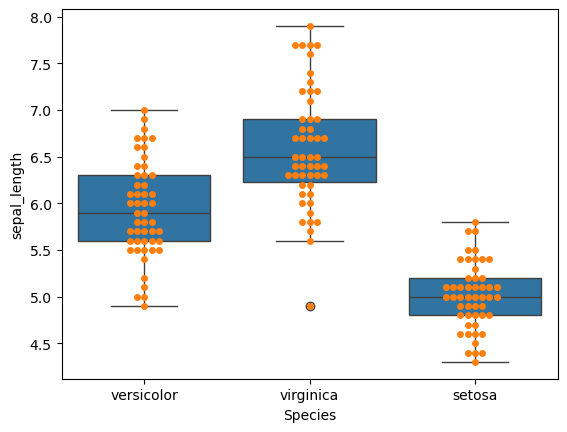

In [6]:
sns.boxplot(data=iris, x='Species', y='sepal_length');
sns.swarmplot(data=iris, x='Species', y='sepal_length');


Boxplots usually have a horizontal bar inside the box to represent the median value. But linear models compare means not medians. So I've removed the medians and replaced them by white circles representing the means.


There are clear differences between the species. Setosa has the shortest sepal length and virginica the longest. 

Mean sepal length of versicolor does not seem to vary much between the three sites. However, the mean sepal length of virginica growing in marsh seems to be longer than in field and roadside (compare orange box to blue and green boxes). And sepal length of setosa in field seems to be longer than in marsh and roadside. So "Site" might interact with "Species" to affect sepal length.

However, there is a lot of variability in sepal length in all categories so it is not clear if there are real differences or that the apparent differences are due to the randomness of sampling. For that we need to fit a linear model to the data and do some stats.

## ANOVA to test null hypothesis that all means are the same

In [70]:
test = anova_oneway(iris['sepal_length'], iris['Species'], use_var='equal')
print(test)

statistic = 119.2645021845045
pvalue = 1.6696691907695076e-31
df = (2.0, 147.0)
df_num = 2.0
df_denom = 147.0
nobs_t = 150.0
n_groups = 3
means = [5.006 5.936 6.588]
nobs = [50. 50. 50.]
vars_ = [0.12424898 0.26643265 0.40434286]
use_var = equal
welch_correction = True
tuple = (119.2645021845045, 1.6696691907695076e-31)


## Tukey's HSD (Honest Significant Difference) all-pairs test for significance

In [68]:
test = pairwise_tukeyhsd(iris['sepal_length'], iris['Species'])
print(test)


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------


In [69]:
print(test.pvalues)

[2.42028619e-14 2.15383267e-14 8.28755409e-09]


## Report the outcome

Mean sepal length of versicolor irises is 0.9 cm (95% CI [0.7, 1.1] cm) longer than setosa irises (*t* = 9.0, 1.9x10^-5^). Mean sepal length of virginica irises is 1.6 cm (95% CI [1.4, 1.8] cm) longer than setosa irises (*t* = 15.4, *p* = 7x10^-11^). There is insufficient evidence that site affects sepal length and for an interactions between site and iris species. 